# Usage


In [1]:
### Colab setup ###
from importlib import util
from pathlib import Path
import subprocess, sys, os

# detect Colab
try:
    import google.colab

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ensure mtphandler is available
PKG, REPO_URL, CLONE_DIR = (
    "mtphandler",
    "https://github.com/FAIRChemistry/MTPHandler.git",
    Path("MTPHandler"),
)
if util.find_spec(PKG) is None:  # not installed → clone + pip install
    subprocess.run(["git", "clone", "--quiet", REPO_URL], check=True)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "."], cwd=CLONE_DIR, check=True
    )

from mtphandler import PlateManager  # noqa: E402

# Colab‑specific tweaks
if IN_COLAB:
    # kill bogus proxy vars that break outbound HTTPS
    for v in ("http_proxy", "https_proxy", "HTTP_PROXY", "HTTPS_PROXY"):
        os.environ.pop(v, None)

    os.chdir("/content/MTPHandler/docs/examples")


---

The following example demonstrates, how the `PlateManager` can be used to process the data from a 96-well plate reader. The workflow consists of the following steps:

1. Load the data of a plate from the devices' output file.
2. Define the molecules and enzymes present in the assay.
3. Define the initial concentrations of each molecule and enzyme for the respective wells.
4. Blank the plate with respect to the molecules and enzymes present in each well.
5. Create a calibration model for the detected molecule.
6. Transform the data to concentration values in the EnzymeML format.

__Experimental scenario__

This notebook reads a Thermo Fisher Varioskan ALF export (`SkanIt` Excel) with `PlateManager.read_varioskan`. The absorbance values are the instrument data. The species and initial concentrations are a mock layout, stored in `data/plate_map_varioskan.xlsx`, so the same processing functions can be shown on the wells that were actually measured.

The export is an endpoint measurement at 344 nm and 346 nm. Filled wells are A7–A12, B7–B12, C7–C12, D7–D12, E7, E8, F7 and F8. Because two wavelengths were measured, `wavelength` is passed to blanking, calibration and the EnzymeML export. The processing below uses 344 nm.

| Wells | Mock content |
| --- | --- |
| A7–A12 and B7–B12 | TNB calibration, 250 to 25 µM, in duplicate |
| C7–C11 | McSAHH with SAH, DTNB and TNB as product |
| C12 | McSAHH control |
| D7–D9 | MeSAHH with SIH, DTNB and TNB as product |
| D10 | MeSAHH control |
| D11 | SIH control |
| D12 | SAH control |
| E7 and F7 | Buffer |
| E8 | MtSAHH control |
| F8 | MiSAHH control |

## Read data

The `PlateManager` class provides a method to read the data from a range of different plate readers. Varioskan ALF files are read with `read_varioskan`.


In [2]:
from pathlib import Path

from mtphandler import PlateManager

DATA_DIR = Path("data")
if not (DATA_DIR / "calibration_varioskan.xlsx").exists():
    DATA_DIR = Path("docs/examples/data")

# Define the path to the data file
path = DATA_DIR / "calibration_varioskan.xlsx"

# Read the data file and create a PlateManager object called `plate`
plate = PlateManager.read_varioskan(
    path=path,
    ph=7.4,
    name="Varioskan mock assay",
)

# Endpoint exports store one time point on each measurement.
# The plate heatmap is drawn when the plate itself has a single time entry.
plate.plate.times = [0.0]

# Visualize the data
plate.visualize(zoom=False, wavelengths=[344], darkmode=False)


## Define Molecules and Proteins

After the plate is loaded, the species which were used in the assay need to be defined. this is done by using the `define_molecule` and `define_protein` respectively.

### Define Molecules

__Required arguments:__

- `id`: An arbitrary identifier for the molecule. Please note that the identifier may not contain spaces or special characters except for underscores.
- `pubchem_cid`: The PubChem Compound ID of the molecule. You can find the PubChem CID by searching for the molecule on the [PubChem website](https://pubchem.ncbi.nlm.nih.gov/). If the PubChem CID is not available, you can set the `pubchem_cid` to `-1` to indicate that the molecule is not present in the PubChem database.

__Optional arguments:__

- `name`: The name of the molecule. If the pubchem_cid is provided, the name is retrieved from the PubChem database. If the PubChem ID is not available, the name must be provided manually.
- `constant`: Whether or not the concentration of the molecule is constant. Default is `False`.


In [3]:
# Define molecules
BUFFER = plate.define_molecule(
    id="BUFFER", pubchem_cid=-1, name="Buffer", constant=True
)

TNB = plate.define_molecule(id="TNB", pubchem_cid=6254, constant=False)

SAH = plate.define_molecule(id="SAH", pubchem_cid=439155, constant=False)

SIH = plate.define_molecule(id="SIH", pubchem_cid=135618563, constant=False)

Hyc = plate.define_molecule(id="Hyc", pubchem_cid=91552, constant=False)

DTNB = plate.define_molecule(id="DTNB", pubchem_cid=6254, constant=False)


### Define Proteins

Proteins are defined in a similar way as molecules. To define a protein, the `define_protein` method is used.

__Required arguments:__

- `id`: An arbitrary identifier for the protein. Please note that the identifier may not contain spaces or special characters except for underscores.
- `name`: Arbitrary name of the protein.

__Optional arguments:__

- `uniprot_id`: The UniProt ID of the protein. You can find the UniProt ID by searching for the protein on the [UniProt website](https://www.uniprot.org/).
- `sequence`: The amino acid sequence of the protein.
- `constant`: Whether or not the concentration of the protein is constant throughout the assay. Default is `True`.


In [4]:
McSAHH = plate.define_protein(
    id="McSAHH", name="Methanocella conradii SAHH", constant=True
)

MeSAHH = plate.define_protein(
    id="MeSAHH",
    name="Methanohalobium evestigatum SAHH",
    constant=True,
    uniprot_id="P9WGV3",
)

MiSAHH = plate.define_protein(
    id="MiSAHH", name="Methanocaldocossus infernus SAHH", constant=True
)

MtSAHH = plate.define_protein(
    id="MtSAHH", name="Methanothrix thermoacetophila SAHH", constant=True
)


## Assign initial concentrations

After defining the molecules and proteins, an Excel spreadsheet can be generated using the `create_assignment_spreadsheet` method to assign the initial concentrations and pH values for each species in the respective wells. The spreadsheet can then be filled out with the respective initial conditions.

To read the Excel file, the `assign_init_conditions_from_spreadsheet` method is used. Therefore, only the `path` and the `concentration_unit` arguments are required. This method goes through the sheets of the Excel spreadsheet and assigns the initial concentration from the plate map to the respective well.

__Requirements structure of the Excel spreadsheet:__

- Leaving cells empty means that the respective species in not present in the well over the course of the experiment.
- Products of the reaction need to be set to a concentration of 0.

The mock concentrations for this plate are already filled in `data/plate_map_varioskan.xlsx`.


In [5]:
# Create spreadsheet
plate.create_assignment_spreadsheet(path=DATA_DIR / "plate_map_varioskan.xlsx")

# Blank Plate from plate map
plate.assign_init_conditions_from_spreadsheet(
    conc_unit="umol / l",
    path=DATA_DIR / "plate_map_varioskan.xlsx",
)


File data/plate_map_varioskan.xlsx already exists. Set 'overwrite=True' to overwrite.

📍 Assigned 86 initial concentration conditions for  ['SAH', 'BUFFER', 'SIH', 'Hyc', 'McSAHH', 'MeSAHH', 'TNB', 
'DTNB', 'MiSAHH', 'MtSAHH'] from data/plate_map_varioskan.xlsx to the plate.

## Blanking of the plate

### Automatic blanking

Since the initial concentrations of the molecules and proteins are defined, the plate can be blanked with respect to the molecules and proteins and their respective concentration present in each well. The `blank_species` method is used to blank the plate. The method takes a `species`, which is one of the previously defined molecules or proteins, and the `wavelength` for which the blanking should be performed. The `wavelength` is optional as long as only one wavelength was measured. If multiple wavelengths were measured, the `wavelength` argument is required. If the `silent` argument is not set to `True`, the method will print the mean absorption of the species at the respective concentration and the wells used for the calculation.

Make sure to blank the buffer first, before blanking the other species. If done the other way around, the wells which can be used to calculate the contribution of a species to the measured signal are not correctly identified.


In [6]:
WAVELENGTH = 344

# First the buffer
plate.blank_species(BUFFER, wavelength=WAVELENGTH)

# Then the all other species
plate.blank_species(SAH, wavelength=WAVELENGTH)
plate.blank_species(SIH, wavelength=WAVELENGTH)
plate.blank_species(McSAHH, wavelength=WAVELENGTH)
plate.blank_species(MeSAHH, wavelength=WAVELENGTH)
plate.blank_species(MiSAHH, wavelength=WAVELENGTH)
plate.blank_species(MtSAHH, wavelength=WAVELENGTH)


2026-11-19 14:27:28.649 | INFO     | mtphandler.plate_manager:_get_conc_blank_mapping:1084 - Mean absorption of Buffer (BUFFER) at 50.0 umol / l: 0.1204 ± 2%  calculated based on wells ['E7', 'F7'].


2026-11-19 14:27:28.650 | INFO     | mtphandler.plate_manager:_apply_blank:963 - Blanked 28 wells containing Buffer.


2026-11-19 14:27:28.650 | INFO     | mtphandler.plate_manager:_get_conc_blank_mapping:1084 - Mean absorption of Adenosylhomocysteine (SAH) at 200.0 umol / l: 0.2256 ± 0%  calculated based on wells ['D12'].


2026-11-19 14:27:28.651 | INFO     | mtphandler.plate_manager:_apply_blank:963 - Blanked 6 wells containing Adenosylhomocysteine.


2026-11-19 14:27:28.651 | INFO     | mtphandler.plate_manager:_get_conc_blank_mapping:1084 - Mean absorption of S-Inosylhomocysteine (SIH) at 200.0 umol / l: 0.4204 ± 0%  calculated based on wells ['D11'].


2026-11-19 14:27:28.651 | INFO     | mtphandler.plate_manager:_apply_blank:963 - Blanked 4 wells containing S-Inosylhomocysteine.


... (4 outputs left out)

2026-11-19 14:27:28.653 | INFO     | mtphandler.plate_manager:_get_conc_blank_mapping:1084 - Mean absorption of Methanocaldocossus infernus SAHH (MiSAHH) at 5.0 umol / l: 0.2028 ± 0%  calculated based on wells ['F8'].


2026-11-19 14:27:28.653 | INFO     | mtphandler.plate_manager:_apply_blank:963 - Blanked 1 wells containing Methanocaldocossus infernus SAHH.


2026-11-19 14:27:28.653 | INFO     | mtphandler.plate_manager:_get_conc_blank_mapping:1084 - Mean absorption of Methanothrix thermoacetophila SAHH (MtSAHH) at 5.0 umol / l: 0.2189 ± 0%  calculated based on wells ['E8'].


2026-11-19 14:27:28.654 | INFO     | mtphandler.plate_manager:_apply_blank:963 - Blanked 1 wells containing Methanothrix thermoacetophila SAHH.


### Manually changing the absorption contribution of a species

In some cases, it is already knows that a certain species does not contribute to the measured signal. In this case, the absorption contribution of the species can be set to zero using the `set_absorption_contribution` method. The method takes the `species` for which the absorption contribution should be set to zero and the `wavelength` at which the measurements were taken. The `wavelength` is optional as long as only one wavelength was measured. If multiple wavelengths were measured, the `wavelength` argument is required.

In this mock assay, `DTNB` is set not to absorb at 344 nm, and no separate DTNB control wells are on the plate.


In [7]:
plate.set_absorption_contribution(
    species=DTNB,
    contributes_to_signal=False,
    wavelength=WAVELENGTH,
)


Set signal contribution of 5,5'-Dithiobis(2-nitrobenzoic Acid) (DTNB) at 344 nm to False.

## Create calibration model

__Initialize a calibrator:__

Next a calibration model for later quantification of the detected molecule `TNB` is created. The `get_calibrator` method is used to create a `Calibrator` object, which facilitates the process of creating and choosing a calibration model for a molecule. The method takes the `species` for which the calibration model should be created and the `wavelength` at which the measurements were taken. The `wavelength` is optional as long as only one wavelength was measured. If multiple wavelengths were measured, the `wavelength` argument is required.

The method returns a `Calibrator`. By default the calibrator comes with a linear, quadratic, and cubic calibration model, which do not consider a parameter for the intercept. Thus catering the assumption that the signal at zero concentration is zero, which is the case for correctly blanked data.

__Fit and visualize the calibration models:__

After initializing the calibrator object, the predefined models can be fitted by calling the `fit_models` and `visualize` method. Then, an overview with statistical parameters as well as the fitted calibration models are displayed.


In [8]:
# Initialize the calibrator for TNB
TNB_calibrator = plate.get_calibrator(TNB, wavelength=WAVELENGTH)

# Fit and visualize the calibration models
TNB_calibrator.fit_models()
TNB_calibrator.visualize()


🔎 Found 12 wells containing 5,5'-Dithiobis(2-nitrobenzoic Acid) (TNB).
['A7', 'A8', 'A9', 'A10', 'A11', 'A12', 'B7', 'B8', 'B9', 'B10', 'B11', 'B12']
✅ Models have been successfully fitted.


                                                  Model Overview                                                  
┏━━━━━━━━━━━━┳━━━━━┳━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Model Name ┃ AIC ┃ R squared ┃ RMSD   ┃ Equation                          ┃ Relative Parameter Standard Errors ┃
┡━━━━━━━━━━━━╇━━━━━╇━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ cubic      │ -71 │ 0.9411    │ 0.0412 │ a * TNB + b * TNB**2 + c * TNB**3 │ a: 22.9%, b: 64.3%, c: 75.5%,      │
│ linear     │ -70 │ 0.915     │ 0.0495 │ a * TNB                           │ a: 4.5%,                           │
│ quadratic  │ -69 │ 0.9312    │ 0.0445 │ a * TNB + b * TNB**2 + c          │ a: 27.5%, b: 84.4%, c: 252.3%,     │
└────────────┴─────┴───────────┴────────┴───────────────────────────────────┴────────────────────────────────────┘

__Choose best calibration model:__

After considering the statistical parameters of the fitted calibration models, the best calibration model can be chosen which will finally be used to quantify the detected molecule. Therefore, the desired model is first registered with the calibrator, before it is added to the molecule for which the calibration was conducted.

For this mock series the quadratic model has the lowest AIC, so that model is registered.


In [9]:
# Add the quadratic model to the Standard of the calibrator
TNB_calibrator.add_model_to_standard(model="quadratic")

# Register the calibrator standard to the `TNB` molecule
TNB.standard = TNB_calibrator.standard


## Convert to EnzymeML

Finally, the enriched and processed data can be transformed into an `EnzymeMLDocument` object. this is done by calling the `to_enzymeml` method.

__Required arguments:__

- `detected_molecule`: The molecule that was detected in the assay.

__Optional arguments:__

- `name`: An optional name for the EnzymeML document. If not provided, the name of the assay is used.
- `catalyzed_only`: If set to `True`, only wells containing one or more proteins and the `detected_molecule` are included in the EnzymeML document. Default is `True`.
- `well_ids`: Optionally, only a subset of wells can be included in the EnzymeML document by providing a list of well IDs.
- `to_concentration`: If set to `True`, the measured signals are converted to concentrations using defined calibration models. Default is `False`.
- `extrapolate`: If set to `True`, the calibration model is used to extrapolate the concentration of the detected molecule in wells where the signal was below or above the detection limit. Default is `False`.
- `wavelength`: The wavelength at which the measurements were taken. If only one wavelength was measured, the `wavelength` argument is optional. If multiple wavelengths were measured, the `wavelength` argument is required.


In [10]:
enzml_mc = plate.to_enzymeml(
    name="McSAHH mock assay",
    detected_molecule=TNB,
    well_ids=["C7", "C8", "C9", "C10", "C11"],
    to_concentration=True,
    extrapolate=True,
    catalyzed_only=True,
    wavelength=WAVELENGTH,
)


✅ Added measurements from 5 wells with concentration values to EnzymeMLDocument


To quickly inspect the generated `EnzymeMLDocument`, the data can be visualized with the following code snippet. This export has one time point per well, so each trace is a single concentration.


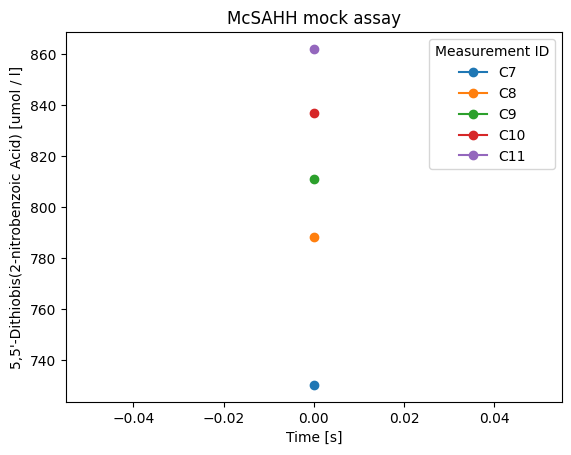

In [11]:
from matplotlib import pyplot as plt

# Iterate over all measurements in the EnzymeML document
# and plot the data if there is any
for measurement in enzml_mc.measurements:
    for species in measurement.species_data:
        if species.data:
            measured_species = species
            plt.plot(species.time, species.data, marker="o", label=measurement.id)

# get the name of the species that has data
measured_species = enzml_mc.filter_small_molecules(
    id=measured_species.species_id
)[0]

# add legend and labels
plt.xlabel("Time [s]")
plt.ylabel(f"{measured_species.name} [{species.data_unit.name}]")
plt.title(f"{enzml_mc.name}")
plt.legend(title="Measurement ID")
plt.show()


### Serialize the EnzymeML Document

With the following code snippet the generated `EnzymeMLDocument` can be saved as an `.json` file, or as an SBML `.xml` file.


In [12]:
from pyenzyme import EnzymeMLDocument
import json

enzymeml_path = DATA_DIR / "enzymeml_varioskan_mock.json"

# Save the EnzymeML document to a file
with open(enzymeml_path, "w") as file:
    file.write(enzml_mc.model_dump_json(indent=4))

# Read the EnzymeML document from a file
with open(enzymeml_path, "r") as file:
    loaded_enzymeml = EnzymeMLDocument(**json.load(file))
